In [93]:
import io
import itertools
import json
import os

import open_clip
import pandas as pd
import torch
from PIL import Image
from matplotlib import pyplot as plt
from torch.utils.data.dataloader import DataLoader

from homework_3.functions import parse_img, api_response_to_tensor

In [94]:
class ClipModel(torch.nn.Module):
    def __init__(self, model_name="ViT-B-32", pretrained="laion2b_s34b_b79k"):
        super().__init__()
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.clip_backbone, _, self.preprocess = open_clip.create_model_and_transforms(model_name=model_name,
                                                                                       pretrained=pretrained)
        for p in self.clip_backbone.parameters():
            p.requires_grad = False
        self.clip_backbone.eval()
        self.tokenizer = open_clip.get_tokenizer(model_name)

        self.concept_labels = [["class1", "class2"], ["class3", "class4"]]

        self.concept1_tokens = self.tokenizer(self.concept_labels[0])
        self.concept2_tokens = self.tokenizer(self.concept_labels[1])

        self.concept1_class_features = self.clip_backbone.encode_text(self.concept1_tokens)
        self.concept1_class_features /= self.concept1_class_features.norm(dim=-1, keepdim=True)
        self.concept1_class_features = self.concept1_class_features.to(self.device)

        self.concept2_class_features = self.clip_backbone.encode_text(self.concept2_tokens)
        self.concept2_class_features /= self.concept2_class_features.norm(dim=-1, keepdim=True)
        self.concept2_class_features = self.concept2_class_features.to(self.device)

        self.head_concept1 = torch.nn.Linear(self.clip_backbone.visual.output_dim,
                                             self.clip_backbone.visual.output_dim)
        self.head_concept2 = torch.nn.Linear(self.clip_backbone.visual.output_dim,
                                             self.clip_backbone.visual.output_dim)

        self.clip_backbone.to(self.device)
        self.head_concept1.to(self.device)
        self.head_concept2.to(self.device)

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        with torch.no_grad():
            image_features = self.clip_backbone.encode_image(images)

        concept1_features = self.head_concept1(image_features)
        concept2_features = self.head_concept2(image_features)

        concept1_features = concept1_features / concept1_features.norm(dim=-1, keepdim=True)
        concept2_features = concept2_features / concept2_features.norm(dim=-1, keepdim=True)

        concept1_similarity = (100.0 * concept1_features @ self.concept1_class_features.T).softmax(dim=-1)
        concept2_similarity = (100.0 * concept2_features @ self.concept2_class_features.T).softmax(dim=-1)
        return torch.cat((concept1_similarity, concept2_similarity), dim=1)


In [95]:
class ApiResponsesDataset(torch.utils.data.Dataset):
    def __init__(self, clip_preprocess, img_dir="../img", img_series=None, responses_cache="../cache/responses.json"):
        super().__init__()

        self.clip_preprocess = clip_preprocess
        self.responses_json = json.load(open(responses_cache, "r"))

        self.raw_images = [Image.open(f"{img_dir}/{p}") for p in os.listdir(img_dir)]
        self.raw_images.extend([Image.open(io.BytesIO(i['bytes'])) for i in img_series])

        self.data = []
        self.labels = []

        self._preprocess()

    def _preprocess(self):
        self.data = [self.clip_preprocess(raw_img) for raw_img in self.raw_images]

        try:
            for raw_img in self.raw_images:
                _, img_hash = parse_img(raw_img)
                response = self.responses_json[img_hash]
                label = api_response_to_tensor(response)
                self.labels.append(label)
        except KeyError:
            exit(f"Dataset integrity error. Not all images have responses.")

        assert len(self.data) == len(self.labels), "Unequal amount of data and labels loaded"

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        return self.data[index], self.labels[index]

In [96]:
# TODO Add validation
def train_model(model, optimizer, criterion, train_data, num_epochs):
    losses = []
    for epoch in range(num_epochs):
        print(f"Epoch {epoch + 1}/{num_epochs}")
        epoch_loss = 0.0
        for data, labels in train_data:
            if torch.cuda.is_available():
                data = data.cuda()
                labels = labels.cuda()
            optimizer.zero_grad()
            outputs = model(data)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        losses.append(epoch_loss / len(train_data))
        print(f"Train loss: {losses[-1]}")

    plt.plot(losses)
    plt.title("Loss curve")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.show()

    return model



In [99]:
WEIGHTS_DIR = "../weights"
RANDOM_SEED = 161
BATCH_SIZE = 2
LEARNING_RATE = 1e-4
NUM_EPOCHS = 25
NAME = f"{NUM_EPOCHS}_{BATCH_SIZE}"

torch.random.manual_seed(RANDOM_SEED)

clip_model = ClipModel()

df = pd.read_parquet("../datasets/cifar100_train.parquet")
series = df.img[:100]

dataset = ApiResponsesDataset(clip_model.preprocess, img_series=series)
train_dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

adam_optimizer = torch.optim.Adam(
    itertools.chain(clip_model.head_concept1.parameters(), clip_model.head_concept2.parameters()), lr=LEARNING_RATE)

crossEntropyLoss = torch.nn.CrossEntropyLoss()

Epoch 1/25
Train loss: 2.606646979296649
Epoch 2/25
Train loss: 2.5311334088996604
Epoch 3/25
Train loss: 2.483041140768263
Epoch 4/25
Train loss: 2.4516350825627646
Epoch 5/25
Train loss: 2.4255970363263732
Epoch 6/25
Train loss: 2.4058078085934675
Epoch 7/25
Train loss: 2.398981182663529
Epoch 8/25
Train loss: 2.3909287761758873
Epoch 9/25
Train loss: 2.391128420829773
Epoch 10/25
Train loss: 2.3916621517252037
Epoch 11/25
Train loss: 2.3877450183585838
Epoch 12/25
Train loss: 2.3824259484255754
Epoch 13/25
Train loss: 2.3817721561149314
Epoch 14/25
Train loss: 2.3810687550791987
Epoch 15/25
Train loss: 2.3835334557074086
Epoch 16/25
Train loss: 2.3845089497389615
Epoch 17/25
Train loss: 2.381774977401451
Epoch 18/25
Train loss: 2.384599217662105
Epoch 19/25
Train loss: 2.3820127425370394
Epoch 20/25
Train loss: 2.3796987489417747
Epoch 21/25
Train loss: 2.3809947349407055
Epoch 22/25
Train loss: 2.3802058078624584
Epoch 23/25
Train loss: 2.381790178793448
Epoch 24/25
Train loss: 2.3

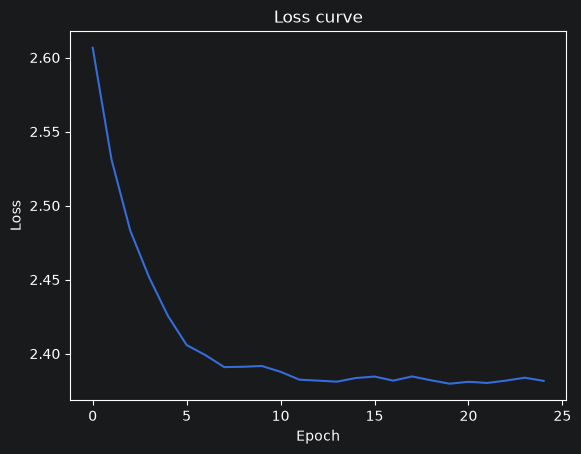

In [100]:
trained_model = train_model(model=clip_model,
                            optimizer=adam_optimizer,
                            criterion=crossEntropyLoss,
                            train_data=train_dataloader,
                            num_epochs=NUM_EPOCHS)

torch.save(trained_model.head_concept1, f"{WEIGHTS_DIR}/concept1_{NAME}.pth")
torch.save(trained_model.head_concept2, f"{WEIGHTS_DIR}/concept2_{NAME}.pth")

